# El valor del suelo en Bogotá

Cuánto vale el m² de terreno, dónde se está valorizando, dónde están las zonas
de empresas y —lo que faltaba en el proyecto anterior— **qué lo explica**,
combinando ubicación, morfología de lo construido, estrato y uso.

Todo sale de la tabla que arma `src/tabla.py`: una fila por manzana urbana con
su precio de referencia de Catastro y las variables de cada fuente. La serie
2017-2026 se lee aparte.

In [1]:
import sys
from pathlib import Path

import geopandas as gpd
import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.linear_model import RidgeCV
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.model_selection import GroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

sys.path.insert(0, str(Path.cwd().parent / "src"))
import config as C

AZUL, VERDE, NARANJA, ROJO, GRIS = "#264653", "#2a9d8f", "#f4a261", "#e76f51", "#b9c2c7"
TAM_MAPA = (5, 8)                           # ancho, alto de cada mapa
CORTES = [0, 1, 2, 3, 5, 8, 15, np.inf]     # rangos de precio de los mapas, en millones

def pesos(x, pos=None):
    return "%.1f M" % (x / 1e6) if x >= 1e6 else "%.0f k" % (x / 1e3)

mz = gpd.read_file(C.TABLA)
print("%d manzanas urbanas con precio, %d columnas" % mz.shape)

41570 manzanas urbanas con precio, 39 columnas


## 1. El valor del suelo en 2026

Primero el precio solo, antes de compararlo con nada.

el 10% mas caro vale 5.2 veces el 10% mas barato


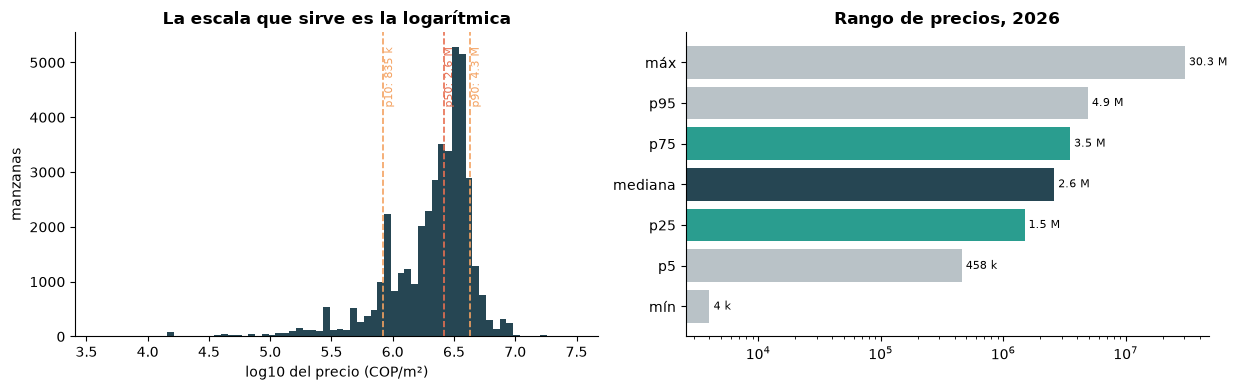

In [2]:
p = mz["cop_m2"]
fig, ax = plt.subplots(1, 2, figsize=(12.5, 4))

ax[0].hist(np.log10(p), bins=70, color=AZUL)
for q, color in [(10, NARANJA), (50, ROJO), (90, NARANJA)]:
    v = np.percentile(p, q)
    ax[0].axvline(np.log10(v), color=color, ls="--", lw=1.2)
    ax[0].text(np.log10(v), ax[0].get_ylim()[1] * .95, " p%d: %s" % (q, pesos(v)),
               rotation=90, va="top", fontsize=8, color=color)
ax[0].set_xlabel("log10 del precio (COP/m²)"); ax[0].set_ylabel("manzanas")
ax[0].set_title("La escala que sirve es la logarítmica", fontweight="bold")

etiquetas = ["mín", "p5", "p25", "mediana", "p75", "p95", "máx"]
valores = [p.min(), *np.percentile(p, [5, 25, 50, 75, 95]), p.max()]
barras = ax[1].barh(etiquetas, valores, color=[GRIS, GRIS, VERDE, AZUL, VERDE, GRIS, GRIS])
ax[1].set_xscale("log")
for b, v in zip(barras, valores):
    ax[1].text(v * 1.08, b.get_y() + b.get_height() / 2, pesos(v), va="center", fontsize=8)
ax[1].set_title("Rango de precios, %d" % C.ANIO, fontweight="bold")

for a in ax:
    a.spines[["top", "right"]].set_visible(False)
fig.tight_layout()

print("el 10%% mas caro vale %.1f veces el 10%% mas barato"
      % (np.percentile(p, 90) / np.percentile(p, 10)))

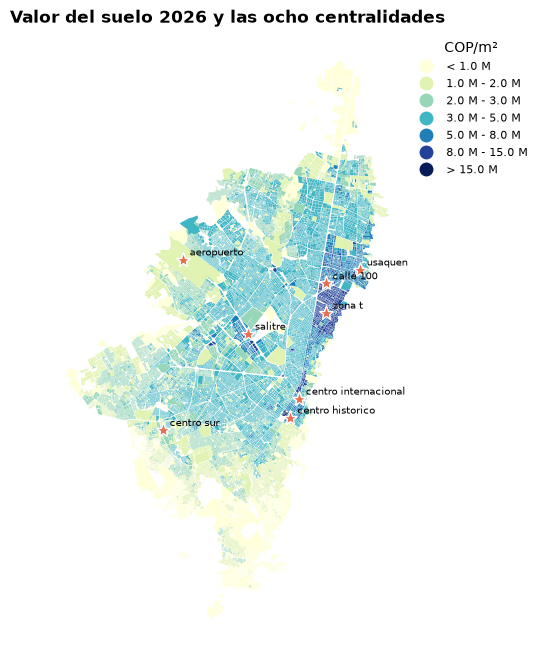

In [3]:
etq = ["< %s" % pesos(b * 1e6) if a == 0 else
       "%s - %s" % (pesos(a * 1e6), pesos(b * 1e6)) if np.isfinite(b) else "> %s" % pesos(a * 1e6)
       for a, b in zip(CORTES[:-1], CORTES[1:])]
mz["rango"] = pd.cut(mz["cop_m2"] / 1e6, CORTES, labels=etq)

fig, ax = plt.subplots(figsize=TAM_MAPA)
mz.plot(column="rango", categorical=True, cmap="YlGnBu", linewidth=0, ax=ax, legend=True,
        legend_kwds={"loc": "upper left", "bbox_to_anchor": (1, 1), "fontsize": 8,
                     "frameon": False, "title": "COP/m²"})
for nombre, (lo, la) in C.CENTROS.items():
    ax.plot(lo, la, "*", color=ROJO, markersize=11, markeredgecolor="white")
    ax.annotate(nombre.replace("_", " "), (lo, la), xytext=(5, 3), textcoords="offset points",
                fontsize=7)
ax.set_title("Valor del suelo %d y las ocho centralidades" % C.ANIO, fontweight="bold")
ax.set_axis_off();

El precio va de 4 000 a 30,3 millones por m², pero el grueso es estrecho: la
mitad de las manzanas está entre 1,5 M y 3,5 M, y el 10 % más caro vale 5,2 veces
el 10 % más barato. Solo 30 manzanas pasan de 15 M.

El mapa ya anticipa lo que la sección 4 va a medir: lo caro es un **corredor
que sube por el oriente** desde el Centro Internacional hasta Usaquén, con un
brazo hacia Salitre. La Plaza de Bolívar no está en el centro de nada caro.

## 2. Dónde se está valorizando la ciudad (2017-2026)

No dónde vale más, sino **dónde sube más rápido**. Los valores son nominales;
como la inflación le pega a todas las manzanas por igual, lo que interesa es la
valorización **frente a la mediana de la ciudad**, que no depende de ella.

**La medida: la tasa anual de crecimiento (TADC).** Con $P_t$ el valor de
referencia del m² de la manzana en el año $t$ (la mediana de sus registros en
`valor_referencia_serie.csv.gz`), es la tasa constante que lleva el precio de
2017 al de 2026:

$$\text{TADC} = \left(\frac{P_{2026}}{P_{2017}}\right)^{1/9} - 1$$

La de la ciudad se calcula igual sobre la mediana de todas las manzanas de cada
año. La valorización frente a la ciudad es la resta, en puntos porcentuales
anuales:

$$\text{vs\_ciudad} = \text{TADC}_{\text{manzana}} - \text{TADC}_{\text{ciudad}}$$

La TADC solo mira el primer y el último año: una manzana que subió parejo y otra
que subió de golpe pueden tener la misma. El notebook 03 la complementa con la
volatilidad y el salto máximo.

In [4]:
serie = pd.read_csv(C.SERIE, dtype={"MANCODIGO": str}).query("V_REF > 0")
ancha = serie.pivot_table(index="MANCODIGO", columns="ANO", values="V_REF", aggfunc="median")

ciudad = ancha.median()
anios = C.ANIO - C.ANIO_INI
tadc_ciudad = (ciudad[C.ANIO] / ciudad[C.ANIO_INI]) ** (1 / anios) - 1

ext = ancha[[C.ANIO_INI, C.ANIO]].dropna()
crec = pd.DataFrame({"precio_%d" % C.ANIO_INI: ext[C.ANIO_INI],
                     "tadc": (ext[C.ANIO] / ext[C.ANIO_INI]) ** (1 / anios) - 1})
crec["vs_ciudad"] = crec["tadc"] - tadc_ciudad
mz = mz.merge(crec, left_on="MANCODIGO", right_index=True, how="left")

print("mediana de la ciudad: %s (%d) -> %s (%d), %.1f%% anual nominal"
      % (pesos(ciudad[C.ANIO_INI]), C.ANIO_INI, pesos(ciudad[C.ANIO]), C.ANIO, 100 * tadc_ciudad))
print("manzanas con precio en %d y %d: %d" % (C.ANIO_INI, C.ANIO, mz["tadc"].notna().sum()))

mediana de la ciudad: 1.2 M (2017) -> 2.6 M (2026), 8.9% anual nominal
manzanas con precio en 2017 y 2026: 40907


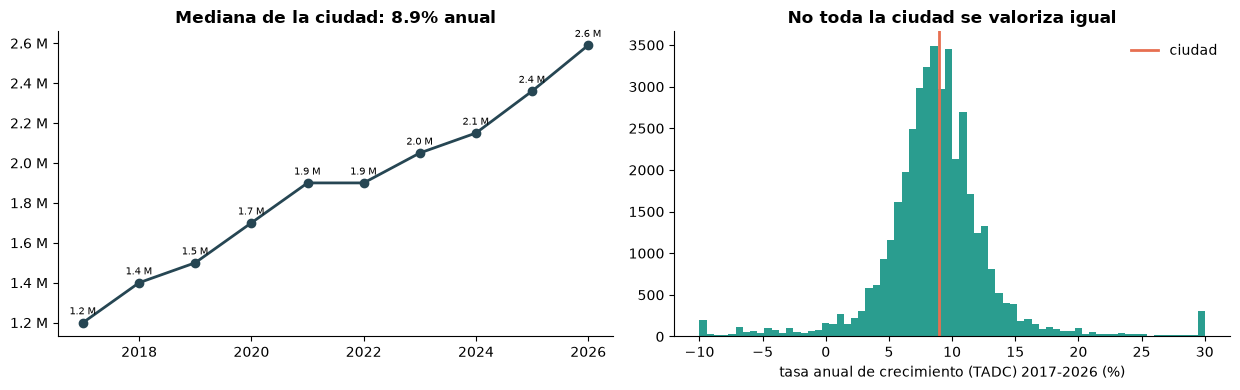

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(12.5, 4))

ax[0].plot(ciudad.index, ciudad.values, "o-", color=AZUL, lw=2)
for x, v in ciudad.items():
    ax[0].annotate(pesos(v), (x, v), xytext=(0, 6), textcoords="offset points",
                   ha="center", fontsize=7)
ax[0].yaxis.set_major_formatter(plt.FuncFormatter(pesos))
ax[0].set_title("Mediana de la ciudad: %.1f%% anual" % (100 * tadc_ciudad), fontweight="bold")

ax[1].hist(100 * mz["tadc"].dropna().clip(-.1, .3), bins=70, color=VERDE)
ax[1].axvline(100 * tadc_ciudad, color=ROJO, lw=2, label="ciudad")
ax[1].set_xlabel("tasa anual de crecimiento (TADC) %d-%d (%%)" % (C.ANIO_INI, C.ANIO))
ax[1].set_title("No toda la ciudad se valoriza igual", fontweight="bold")
ax[1].legend(frameon=False)

for a in ax:
    a.spines[["top", "right"]].set_visible(False)
fig.tight_layout();

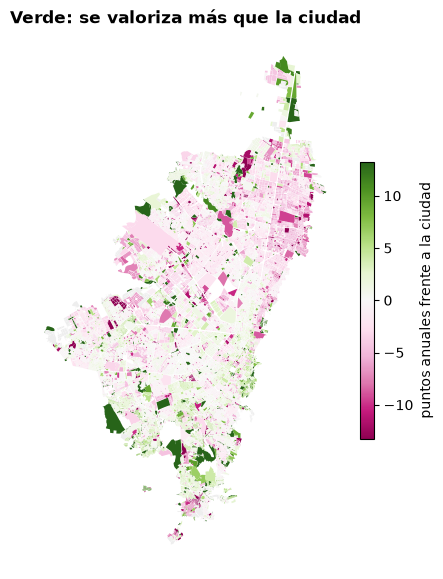

In [6]:
lim = np.nanpercentile(np.abs(100 * mz["vs_ciudad"]), 97)

fig, ax = plt.subplots(figsize=TAM_MAPA)
mz.assign(pts=100 * mz["vs_ciudad"]).plot(
    column="pts", cmap="PiYG", vmin=-lim, vmax=lim, linewidth=0, ax=ax, legend=True,
    missing_kwds={"color": "#eeeeee"},
    legend_kwds={"shrink": .45, "label": "puntos anuales frente a la ciudad"})
ax.set_title("Verde: se valoriza más que la ciudad", fontweight="bold")
ax.set_axis_off();

Spearman precio 2017 vs crecimiento: -0.444
precio mediano 2026 de esos 12 sectores: 1.0 M  (la ciudad: 2.6 M)


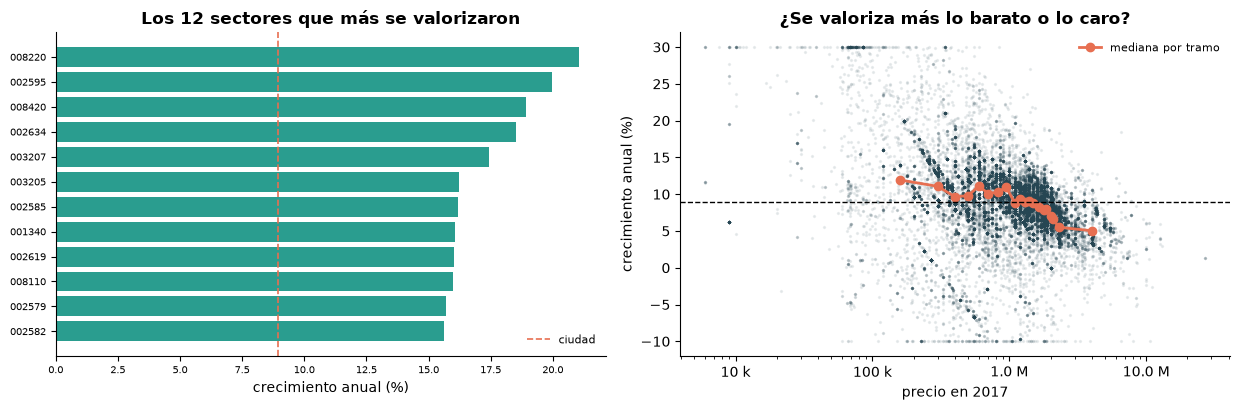

In [7]:
sectores = (mz.dropna(subset=["tadc"]).groupby("sector")
            .agg(manzanas=("tadc", "size"), tadc=("tadc", "median"), precio=("cop_m2", "median"))
            .query("manzanas >= 10"))

fig, ax = plt.subplots(1, 2, figsize=(12.5, 4.2))

top = sectores.nlargest(12, "tadc").iloc[::-1]
ax[0].barh(top.index, 100 * top["tadc"], color=VERDE)
ax[0].axvline(100 * tadc_ciudad, color=ROJO, ls="--", lw=1.2, label="ciudad")
ax[0].set_xlabel("crecimiento anual (%)"); ax[0].tick_params(labelsize=7)
ax[0].set_title("Los 12 sectores que más se valorizaron", fontweight="bold")
ax[0].legend(frameon=False, fontsize=8)

c = mz.dropna(subset=["tadc"])
tramos = c.groupby(pd.qcut(c["precio_%d" % C.ANIO_INI], 20), observed=True).agg(
    x=("precio_%d" % C.ANIO_INI, "median"), y=("tadc", "median"))
ax[1].scatter(c["precio_%d" % C.ANIO_INI], 100 * c["tadc"].clip(-.1, .3), s=2, alpha=.08, color=AZUL)
ax[1].plot(tramos["x"], 100 * tramos["y"], "o-", color=ROJO, lw=2, label="mediana por tramo")
ax[1].axhline(100 * tadc_ciudad, color="k", ls="--", lw=1)
ax[1].set_xscale("log"); ax[1].xaxis.set_major_formatter(plt.FuncFormatter(pesos))
ax[1].set_xlabel("precio en %d" % C.ANIO_INI); ax[1].set_ylabel("crecimiento anual (%)")
ax[1].set_title("¿Se valoriza más lo barato o lo caro?", fontweight="bold")
ax[1].legend(frameon=False, fontsize=8)

for a in ax:
    a.spines[["top", "right"]].set_visible(False)
fig.tight_layout()

print("Spearman precio %d vs crecimiento: %.3f"
      % (C.ANIO_INI, c["precio_%d" % C.ANIO_INI].corr(c["tadc"], method="spearman")))
print("precio mediano %d de esos 12 sectores: %s  (la ciudad: %s)"
      % (C.ANIO, pesos(top["precio"].median()), pesos(mz["cop_m2"].median())))

La mediana de la ciudad pasó de 1,2 M a 2,6 M: 8,9 % anual nominal. Por manzana
la dispersión es grande, y el panel de la derecha explica buena parte: **lo
barato crece más rápido en porcentaje** (Spearman −0,44 entre el precio de 2017 y
el crecimiento). Es reversión a la media: la periferia partía de muy abajo.

Por eso los sectores que más se valorizaron —entre 15,6 % y 21,1 % anual— valen
hoy 1,0 M de mediana, menos de la mitad que la ciudad. Leídos sin corregir, son
una lista de zonas baratas, no de oportunidades. El notebook de clusters hace la
corrección.

## 3. Zonas de empresas

El uso predominante de la manzana —no de cada predio— dice dónde están las zonas
empresariales. Una oficina suelta en un barrio residencial no aparece aquí.

,manzanas,precio,pisos,crec_anual_pct,pct
uso,,,,,
COMERCIO Y OFICINAS,1632,4200000.0,2.1110,7.4,3.9
DEPOSITOS Y PARQUEADEROS,300,3478000.0,1.8150,8.3,0.7
INDUSTRIAL,146,3326000.0,1.3275,10.1,0.4
BODEGAS,741,3300000.0,1.2640,9.4,1.8
RESIDENCIAL,35516,2670000.0,2.3440,8.8,85.4
DOTACIONAL,781,1545063.0,1.9590,7.9,1.9
OTROS,2454,569426.5,1.5075,5.3,5.9


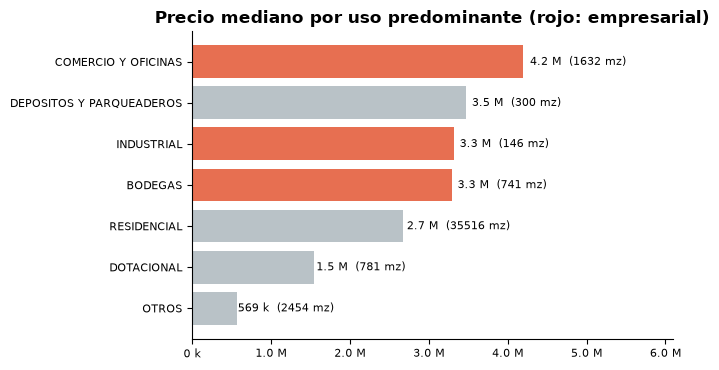

In [8]:
EMPRESA = ["COMERCIO Y OFICINAS", "INDUSTRIAL", "BODEGAS"]

por_uso = (mz.groupby("uso")
           .agg(manzanas=("uso", "size"), precio=("cop_m2", "median"),
                pisos=("pisos_prom_pond", "median"), crec_anual_pct=("tadc", "median"))
           .sort_values("precio"))
por_uso["crec_anual_pct"] = (100 * por_uso["crec_anual_pct"]).round(1)
por_uso["pct"] = (100 * por_uso["manzanas"] / por_uso["manzanas"].sum()).round(1)

fig, ax = plt.subplots(figsize=(7, 3.8))
ax.barh(por_uso.index, por_uso["precio"],
        color=[ROJO if u in EMPRESA else GRIS for u in por_uso.index])
for i, (v, n) in enumerate(zip(por_uso["precio"], por_uso["manzanas"])):
    ax.text(v * 1.02, i, "%s  (%d mz)" % (pesos(v), n), va="center", fontsize=8)
ax.xaxis.set_major_formatter(plt.FuncFormatter(pesos))
ax.set_xlim(0, por_uso["precio"].max() * 1.45)
ax.set_title("Precio mediano por uso predominante (rojo: empresarial)", fontweight="bold")
ax.spines[["top", "right"]].set_visible(False); ax.tick_params(labelsize=8)
fig.tight_layout()

por_uso.iloc[::-1]

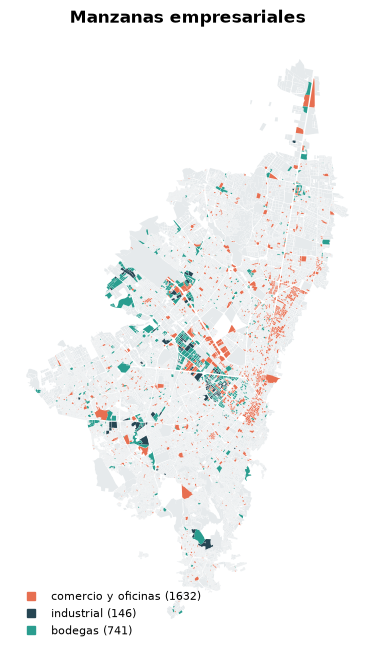

In [9]:
COLOR_USO = {"COMERCIO Y OFICINAS": ROJO, "INDUSTRIAL": AZUL, "BODEGAS": VERDE}

fig, ax = plt.subplots(figsize=TAM_MAPA)
mz[~mz["uso"].isin(EMPRESA)].plot(ax=ax, color="#e6eaec", linewidth=0)
for uso, color in COLOR_USO.items():
    mz[mz["uso"] == uso].plot(ax=ax, color=color, linewidth=0)
ax.legend(handles=[plt.Line2D([], [], marker="s", ls="", color=c,
                              label="%s (%d)" % (u.lower(), (mz["uso"] == u).sum()))
                   for u, c in COLOR_USO.items()], fontsize=8, frameon=False, loc="lower left")
ax.set_title("Manzanas empresariales", fontweight="bold")
ax.set_axis_off();

In [10]:
tipo = np.where(mz["uso"].isin(EMPRESA), "empresarial", "otros usos")
(mz.groupby(tipo)
   .agg(manzanas=("uso", "size"), precio=("cop_m2", "median"),
        crec_anual_pct=("tadc", lambda s: round(100 * s.median(), 2)),
        pisos=("pisos_prom_pond", "median"),
        dist_centro_cercano_km=("dist_centro_cercano_km", "median"))
   .round(2))

,manzanas,precio,crec_anual_pct,pisos,dist_centro_cercano_km
empresarial,2519,3535000.0,8.14,1.68,2.62
otros usos,39051,2580000.0,8.76,2.33,4.20


Comercio y oficinas es el uso más caro (4,2 M de mediana) y ocupa apenas el 3,9 %
de las manzanas. Industria y bodegas valen casi lo mismo entre sí (3,3 M) y más
que lo residencial (2,7 M). Lo más barato es "otros" (569 k), que agrupa lotes y
usos sin clasificar.

Las zonas empresariales están más cerca de alguna centralidad (2,6 km contra
4,2 km del resto) pero se valorizan algo menos: 8,1 % anual contra 8,8 %. Es la
misma reversión a la media de la sección anterior: parten de más arriba.

## 4. Qué explica el precio

El proyecto anterior predecía el valor solo con la ubicación y usaba la
morfología únicamente comprimida en el IVS. Aquí entran las cuatro fuentes por
separado:

| Fuente | Variables |
|---|---|
| **Ubicación** | coordenadas, distancia a las ocho centralidades y a la más cercana, distancia a los cerros, rumbo desde la Plaza de Bolívar, densidad de manzanas alrededor |
| **Morfología** | índice de construcción y de ocupación, pisos promedio y máximo, fracción con 3+ pisos y con sótano, huella media, lotes por hectárea, área y compacidad de la manzana |
| **Estrato** | el socioeconómico, con "sin estratificar" como categoría propia |
| **Uso** | el uso económico predominante |

Se modela `log10` del precio. La validación es por **sector catastral**
(`GroupKFold`, 5 pliegues): ningún sector aparece a la vez en entrenamiento y en
prueba, así el modelo no aprueba por tener la manzana de enfrente.

In [11]:
UBICACION = (["lon", "lat"] + ["dist_%s_km" % n for n in C.CENTROS]
             + ["dist_centro_cercano_km", "dist_cerros_km", "azimut_sin", "azimut_cos",
                "vecinos_500m", "vecinos_1km", "dist_vecino_8_km"])
MORFOLOGIA = ["indice_construccion", "indice_ocupacion", "pisos_prom_pond", "pisos_max",
              "frac_pisos_ge3", "frac_subterraneo", "huella_media_m2", "densidad_lotes_ha",
              "area_manzana_m2", "compacidad"]
FUENTES = {"ubicacion": UBICACION, "morfologia": MORFOLOGIA, "estrato": ["estrato"], "uso": ["uso"]}

d = mz[mz["n_construcciones"].notna()].reset_index(drop=True)
X = d[sum(FUENTES.values(), [])].copy()
X["estrato"] = X["estrato"].astype("category")       # NaN = sin estratificar
X["uso"] = X["uso"].astype("category")
y = np.log10(d["cop_m2"])
sectores_cv = d["sector"]

print("%d manzanas con morfologia, %d variables, %d sectores"
      % (len(d), X.shape[1], sectores_cv.nunique()))

39378 manzanas con morfologia, 29 variables, 1003 sectores


Antes de modelar, la relación de cada variable con el precio por separado. Es
una correlación de rangos, de a una: no dice cuánto aporta cada variable cuando
están todas juntas, pero muestra de dónde viene la señal.

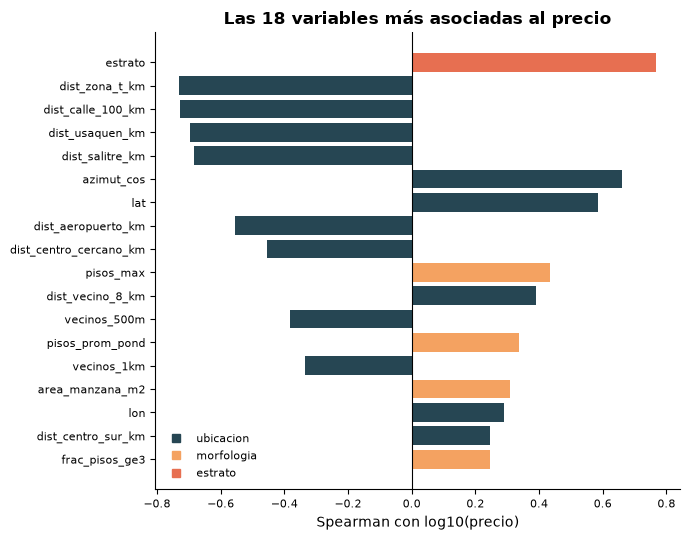

In [12]:
numericas = UBICACION + MORFOLOGIA + ["estrato"]
rho = d[numericas].corrwith(y, method="spearman").sort_values(key=abs)
color_fuente = {"ubicacion": AZUL, "morfologia": NARANJA, "estrato": ROJO}
fuente_de = {v: f for f, vs in FUENTES.items() for v in vs}

top = rho.tail(18)
fig, ax = plt.subplots(figsize=(7, 5.5))
ax.barh(top.index, top.values, color=[color_fuente[fuente_de[v]] for v in top.index])
ax.axvline(0, color="k", lw=.8)
ax.legend(handles=[plt.Line2D([], [], marker="s", ls="", color=c, label=f)
                   for f, c in color_fuente.items()], frameon=False, fontsize=8)
ax.set_xlabel("Spearman con log10(precio)")
ax.set_title("Las 18 variables más asociadas al precio", fontweight="bold")
ax.spines[["top", "right"]].set_visible(False); ax.tick_params(labelsize=8)
fig.tight_layout();

El estrato es lo más asociado al precio (0,77), seguido de la distancia a las
centralidades del norte: Zona T (−0,73), Calle 100 (−0,73), Usaquén (−0,70) y
Salitre (−0,68).

**La distancia al centro histórico no aparece: su correlación con el precio es
−0,05, prácticamente nula.** Estar cerca de la Plaza de Bolívar no encarece el
suelo. Las manzanas cuya centralidad más cercana es el centro histórico son, de
hecho, las de mediana más baja (1,4 M), porque esa zona de influencia abarca todo
el suroriente. Lo mismo pasa con los cerros (−0,02): el borde oriental es caro en
Chapinero y barato en San Cristóbal. Bogotá es policéntrica y su polo de valor
está en el norte.

La morfología aparece más abajo —pisos máximos 0,43, pisos promedio 0,34—: tiene
señal propia, menor que la de la ubicación.

### La escalera por fuentes

Se entrena el mismo LightGBM con distintas combinaciones de fuentes y se mide
fuera de muestra. Las dos primeras filas responden cuánto vale cada fuente
sola; las siguientes, cuánto agrega cada una sobre las anteriores. Al final, una
regresión Ridge con todo, para ver cuánto del resultado viene de que el árbol
capte formas no lineales.

In [13]:
lgbm = lgb.LGBMRegressor(n_estimators=600, learning_rate=.05, num_leaves=31,
                         min_child_samples=40, subsample=.8, subsample_freq=1,
                         colsample_bytree=.8, random_state=C.SEMILLA, verbose=-1)
cv = GroupKFold(n_splits=5)
pliegues = list(cv.split(X, y, sectores_cv))

escalones = {"solo ubicacion": ["ubicacion"],
             "solo morfologia": ["morfologia"],
             "ubicacion + morfologia": ["ubicacion", "morfologia"],
             "+ estrato": ["ubicacion", "morfologia", "estrato"],
             "+ uso (todo)": ["ubicacion", "morfologia", "estrato", "uso"]}

filas, fuera_de_muestra = [], {}
for nombre, fuentes in escalones.items():
    cols = sum((FUENTES[f] for f in fuentes), [])
    pred, r2s = np.zeros(len(d)), []
    for tr, te in pliegues:
        m = clone(lgbm).fit(X.iloc[tr][cols], y.iloc[tr])
        pred[te] = m.predict(X.iloc[te][cols])
        r2s.append(r2_score(y.iloc[te], pred[te]))
    fuera_de_muestra[nombre] = pred
    real, est = d["cop_m2"], 10 ** pred
    filas.append({"modelo": nombre, "variables": len(cols),
                  "R2_log": np.mean(r2s), "R2_desv": np.std(r2s),
                  "MAE": mean_absolute_error(real, est),
                  "err_rel_mediano_%": 100 * np.median(np.abs(est - real) / real)})

# referencia lineal con todo: indicadoras para lo categorico, escalado para lo demas
X_lin = pd.concat([d[UBICACION + MORFOLOGIA],
                   pd.get_dummies(d["estrato"], prefix="E", dummy_na=True),
                   pd.get_dummies(d["uso"], prefix="U")], axis=1).astype(float)
ridge = make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-2, 3, 20)))
pred, r2s = np.zeros(len(d)), []
for tr, te in pliegues:
    pred[te] = clone(ridge).fit(X_lin.iloc[tr], y.iloc[tr]).predict(X_lin.iloc[te])
    r2s.append(r2_score(y.iloc[te], pred[te]))
filas.append({"modelo": "Ridge con todo (lineal)", "variables": X_lin.shape[1],
              "R2_log": np.mean(r2s), "R2_desv": np.std(r2s),
              "MAE": mean_absolute_error(d["cop_m2"], 10 ** pred),
              "err_rel_mediano_%": 100 * np.median(np.abs(10 ** pred - d["cop_m2"]) / d["cop_m2"])})

escalera = pd.DataFrame(filas).set_index("modelo")
escalera["MAE"] = escalera["MAE"].map(pesos)
escalera.round(3)

,variables,R2_log,R2_desv,MAE,err_rel_mediano_%
modelo,,,,,
solo ubicacion,17,0.684,0.027,475 k,10.729
solo morfologia,10,0.511,0.012,735 k,21.720
ubicacion + morfologia,27,0.763,0.018,423 k,10.238
+ estrato,28,0.782,0.010,412 k,9.895
+ uso (todo),29,0.787,0.013,405 k,9.784
Ridge con todo (lineal),41,0.723,0.014,552 k,16.002


La ubicación sola explica el 68 % de la varianza del log-precio en sectores que el
modelo no vio, con un error típico del 10,7 %. La morfología sola llega a 0,51:
menos, pero lejos de ser ruido.

**Juntas suben a 0,76**, 0,08 por encima de la ubicación sola. La morfología trae
información que las coordenadas no tienen: en la misma cuadra no vale lo mismo
una manzana de casas de dos pisos que una de edificios con sótano. El estrato
agrega 0,02 más y el uso apenas 0,005.

El modelo completo queda en **R² 0,787 con un error relativo mediano de 9,8 %**.
La Ridge con las mismas variables se queda en 0,72 y 16 % de error: la diferencia
es la no linealidad —la U invertida de la latitud, los umbrales de distancia—,
que el árbol capta solo.

### Qué fuente pesa más cuando están todas

Importancia por permutación **por bloques**: se desordenan juntas todas las
variables de una fuente y se mide cuánto cae el R². Desordenarlas de a una
subestimaría la ubicación, porque sus 17 variables se cubren entre sí: quitas
una distancia y las otras siete la reemplazan.

,caida_R2,desv
ubicacion,0.996,0.066
morfologia,0.128,0.024
estrato,0.105,0.013
uso,0.010,0.001


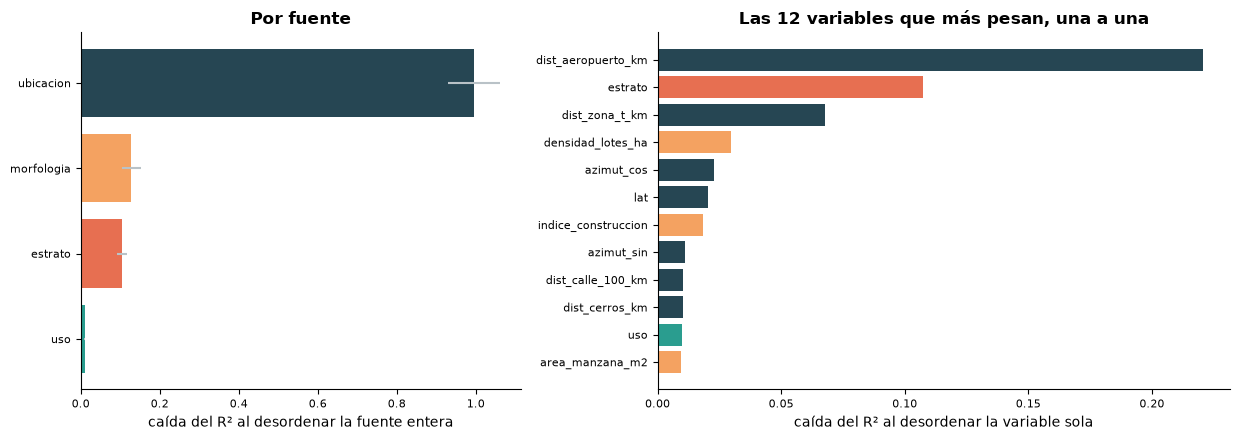

In [14]:
todas = sum(FUENTES.values(), [])
rng = np.random.default_rng(C.SEMILLA)
caida_fuente = {f: [] for f in FUENTES}
caida_variable = {v: [] for v in todas}

for tr, te in pliegues:
    m = clone(lgbm).fit(X.iloc[tr][todas], y.iloc[tr])
    Xte, yte = X.iloc[te][todas], y.iloc[te]
    base = r2_score(yte, m.predict(Xte))
    for f, vs in FUENTES.items():
        orden = rng.permutation(len(Xte))
        Xp = Xte.copy()
        for v in vs:                               # el bloque se mueve junto
            Xp[v] = Xte[v].iloc[orden].set_axis(Xte.index)
        caida_fuente[f].append(base - r2_score(yte, m.predict(Xp)))
    for v in todas:
        Xp = Xte.copy()
        Xp[v] = Xte[v].iloc[rng.permutation(len(Xte))].set_axis(Xte.index)
        caida_variable[v].append(base - r2_score(yte, m.predict(Xp)))

por_fuente = pd.DataFrame({f: [np.mean(c), np.std(c)] for f, c in caida_fuente.items()},
                          index=["caida_R2", "desv"]).T.sort_values("caida_R2")
por_variable = pd.Series({v: np.mean(c) for v, c in caida_variable.items()}).sort_values()

fig, ax = plt.subplots(1, 2, figsize=(12.5, 4.5), gridspec_kw={"width_ratios": [1, 1.3]})
ax[0].barh(por_fuente.index, por_fuente["caida_R2"], xerr=por_fuente["desv"],
           color=[color_fuente.get(f, VERDE) for f in por_fuente.index], ecolor=GRIS)
ax[0].set_xlabel("caída del R² al desordenar la fuente entera")
ax[0].set_title("Por fuente", fontweight="bold")
t = por_variable.tail(12)
ax[1].barh(t.index, t.values, color=[color_fuente.get(fuente_de[v], VERDE) for v in t.index])
ax[1].set_xlabel("caída del R² al desordenar la variable sola")
ax[1].set_title("Las 12 variables que más pesan, una a una", fontweight="bold")
for a in ax:
    a.spines[["top", "right"]].set_visible(False); a.tick_params(labelsize=8)
fig.tight_layout()

por_fuente.iloc[::-1].round(3)

Desordenar toda la ubicación junta tira el R² en 1,0: sin ella el modelo no
sirve. La morfología (0,13) y el estrato (0,10) pesan parecido, y el uso casi
nada (0,01).

Una a una, la variable que más pesa es la distancia al aeropuerto, y no hay que
leerla literal: tiene una correlación de −0,81 con la latitud, así que funciona
como el **eje sur–norte** de la ciudad, no como un efecto del aeropuerto. Le
siguen el estrato y la distancia a la Zona T. De la morfología, lo que más
aporta es la densidad de lotes y el índice de construcción.

### Dónde se equivoca

El residuo fuera de muestra del modelo completo —precio real menos estimado—
sobre el mapa. Rojo: la manzana vale más de lo que el modelo dice; azul: vale
menos. En logaritmo, 0.1 es equivocarse un 26 %.

,manzanas,sesgo,error_tipico
centro_cercano,,,
zona_t,1427,0.000,0.030
aeropuerto,5371,-0.000,0.031
salitre,3377,-0.001,0.032
centro_sur,14944,-0.000,0.041
calle_100,3067,0.002,0.044
centro_internacional,1139,0.005,0.055
centro_historico,7638,0.003,0.056
usaquen,2415,0.001,0.062


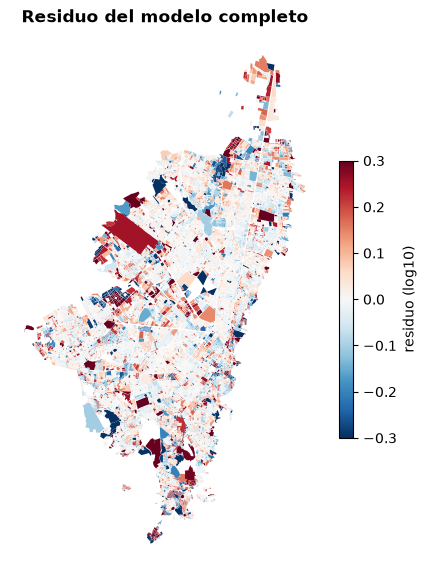

In [15]:
d["residuo"] = y - fuera_de_muestra["+ uso (todo)"]

fig, ax = plt.subplots(figsize=TAM_MAPA)
d.plot(column="residuo", cmap="RdBu_r", vmin=-.3, vmax=.3, linewidth=0, ax=ax, legend=True,
       legend_kwds={"shrink": .45, "label": "residuo (log10)"})
ax.set_title("Residuo del modelo completo", fontweight="bold")
ax.set_axis_off()

(d.assign(abs_res=d["residuo"].abs())
  .groupby("centro_cercano")
  .agg(manzanas=("residuo", "size"), sesgo=("residuo", "median"), error_tipico=("abs_res", "median"))
  .sort_values("error_tipico").round(3))

El modelo no tiene sesgo por zona —la mediana del residuo es prácticamente cero
alrededor de todas las centralidades— pero sí precisión distinta. Donde mejor
acierta es en torno a la Zona T, el aeropuerto y Salitre (0,03 en log, un 7 %);
donde peor, en torno a Usaquén y al centro histórico (0,06, un 15 %).

Tiene sentido: el centro histórico mezcla en pocas cuadras patrimonio, comercio
popular, inquilinatos y renovación, y esa mezcla no la describe ninguna de estas
variables. Usaquén combina el casco fundacional con la ladera y los conjuntos
nuevos del norte.

## 5. Lo que queda

- **Lo caro es un corredor del norte, no un centro.** Las centralidades del norte
  ordenan el precio; la distancia a la Plaza de Bolívar no (ρ = −0,05). Había que
  incluir el centro histórico para poder afirmarlo.
- **La morfología sí importa.** Sobre la ubicación agrega 0,08 de R² y es la
  segunda fuente en peso, a la par del estrato. En el proyecto anterior quedaba
  escondida dentro del IVS.
- **Con las cuatro fuentes el precio se estima con un error típico del 10 %** en
  sectores que el modelo no vio. Es un modelo de nivel: dice cuánto vale una
  manzana hoy, no cuánto va a subir. Eso es el notebook 02.
- **La valorización va en contra del nivel.** Lo barato sube más rápido en
  porcentaje (ρ = −0,44). Una lista de "zonas que más se valorizan" sin
  corregir es una lista de zonas baratas.
- **Lo que falta** son licencias, norma urbanística y transacciones. Los errores
  más grandes —centro histórico, Usaquén— están justo donde esas cosas cambian de
  una cuadra a otra.